# <span style="color:green"> Laboratorio di Simulazione Numerica </span>
## <span style="color:blue">  Tommaso Cardano Chiezzi</span> 

# Esercizio 05.1 — Algoritmo di Metropolis per l'atomo di idrogeno

In questo esercizio viene utilizzato l'algoritmo di Metropolis per campionare le distribuzioni di probabilità associate allo stato fondamentale $1s$ e a uno stato eccitato $2p$ dell'atomo di idrogeno.

L'obiettivo principale è stimare il valor medio della distanza dell'elettrone dal nucleo,

$$
\langle r \rangle,
$$

e confrontare i risultati numerici con i valori teorici:

$$
\langle r \rangle_{1s} = \frac{3}{2}a_0,
$$

$$
\langle r \rangle_{2p} = 5a_0.
$$

Nel seguito si utilizzano unità del raggio di Bohr, ponendo quindi

$$
a_0 = 1.
$$

I valori teorici diventano quindi:

$$
\langle r \rangle_{1s} = 1.5,
\qquad
\langle r \rangle_{2p} = 5.
$$

## Densità di probabilità

Per lo stato fondamentale $1s$ la funzione d'onda è

$$
\Psi_{1,0,0}(r,\theta,\phi)
=
\frac{1}{\sqrt{\pi}}e^{-r},
$$

da cui

$$
|\Psi_{1,0,0}|^2
\propto
e^{-2r}.
$$

Per lo stato eccitato $2p$ considerato nell'esercizio,

$$
\Psi_{2,1,0}(r,\theta,\phi)
\propto
r\,e^{-r/2}\cos\theta.
$$

Utilizzando la relazione

$$
z=r\cos\theta,
$$

si ottiene, in coordinate cartesiane,

$$
|\Psi_{2,1,0}|^2
\propto
z^2e^{-r}.
$$

L'algoritmo di Metropolis utilizza solamente il rapporto tra le probabilità nel punto proposto e nel punto corrente. Le costanti di normalizzazione non devono quindi essere conosciute esplicitamente.

Nel caso di una probabilità di transizione uniforme e simmetrica, la probabilità di accettazione è

$$
A(\mathbf r'|\mathbf r)
=
\min\left[
1,
\frac{p(\mathbf r')}{p(\mathbf r)}
\right].
$$

## Algoritmo di Metropolis

A partire dalla posizione corrente

$$
\mathbf r=(x,y,z),
$$

viene proposta una nuova configurazione

$$
\mathbf r'=(x',y',z')
$$

attraverso uno spostamento uniforme e indipendente sulle tre coordinate:

$$
x'=x+\delta_x,
\qquad
y'=y+\delta_y,
\qquad
z'=z+\delta_z,
$$

con

$$
\delta_i \sim U(-\Delta,\Delta).
$$

Poiché la probabilità di transizione è simmetrica,

$$
T(\mathbf r'|\mathbf r)
=
T(\mathbf r|\mathbf r'),
$$

la probabilità di accettazione di Metropolis si riduce a

$$
A(\mathbf r'|\mathbf r)
=
\min\left[
1,
\frac{p(\mathbf r')}{p(\mathbf r)}
\right].
$$

Se la mossa viene rifiutata, la configurazione successiva della catena coincide con quella precedente.

## Taratura del passo di Metropolis

La nuova posizione viene proposta attraverso uno spostamento uniforme e indipendente sulle tre coordinate:

$$
x' = x + \delta_x,
\qquad
y' = y + \delta_y,
\qquad
z' = z + \delta_z,
$$

con

$$
\delta_i \sim U(-\Delta,\Delta).
$$

Il parametro $\Delta$ controlla quindi l'ampiezza dei passi della catena di Markov.

Un valore troppo piccolo produce un'accettanza elevata, ma anche una forte correlazione tra configurazioni successive. Un valore troppo grande porta invece a molti rifiuti.

Il passo è stato quindi tarato automaticamente mediante brevi simulazioni preliminari, cercando un tasso di accettanza prossimo al $50\%$.

Sono stati ottenuti:

$$
\Delta_{1s}=1.21,
\qquad
\Delta_{2p}=2.9282.
$$

Durante la simulazione di misura i tassi di accettanza risultano circa pari al $50\%$ in entrambi i casi.

La stima progressiva converge rapidamente verso il valore teorico

$$
\langle r\rangle_{1s}=1.5.
$$

All'aumentare del numero di blocchi l'incertezza statistica diminuisce e il valore teorico rimane compatibile con la stima Monte Carlo entro le barre d'errore.

## Equilibrazione della catena di Metropolis

La distribuzione dei punti generati dall'algoritmo di Metropolis coincide con la distribuzione target solamente in modo asintotico.

La configurazione iniziale della catena viene scelta arbitrariamente e, durante i primi passi, il campionamento può quindi dipendere significativamente dalla condizione iniziale.

Prima di iniziare le misure è necessario introdurre una fase di **equilibrazione** (*burn-in*), durante la quale la catena viene fatta evolvere senza utilizzare le configurazioni generate per il calcolo delle osservabili.

Per studiare questo processo vengono considerate, per lo stato fondamentale $1s$, due condizioni iniziali:

- una posizione vicina alla regione tipicamente esplorata dalla distribuzione;
- una posizione volutamente molto lontana dall'origine.

La densità dello stato fondamentale è

$$
p_{1s}(\mathbf r)\propto e^{-2r},
$$

ed è quindi fortemente concentrata vicino all'origine.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
# Caricamento dei dati utilizzati per studiare l'equilibrazione

equil_near_1s = np.loadtxt("Esercizio_05.1/equilibration_1s_near.dat")
equil_far_1s = np.loadtxt("Esercizio_05.1/equilibration_1s_far.dat")

# Estrazione delle colonne
steps_near_1s = equil_near_1s[:, 0]
r_near_1s = equil_near_1s[:, 1]

steps_far_1s = equil_far_1s[:, 0]
r_far_1s = equil_far_1s[:, 1]

### Partenza molto lontana dall'origine

Per rendere evidente il transiente iniziale, la catena viene fatta partire dalla posizione

$$
\mathbf r_0=(1000,0,0),
$$

corrispondente a

$$
r_0=1000\,a_0.
$$

Questa configurazione si trova in una regione in cui la densità di probabilità dello stato $1s$ è estremamente piccola.

Durante i primi passi la catena tende quindi a spostarsi verso regioni a probabilità maggiore, fino a raggiungere la zona caratteristica della distribuzione target.

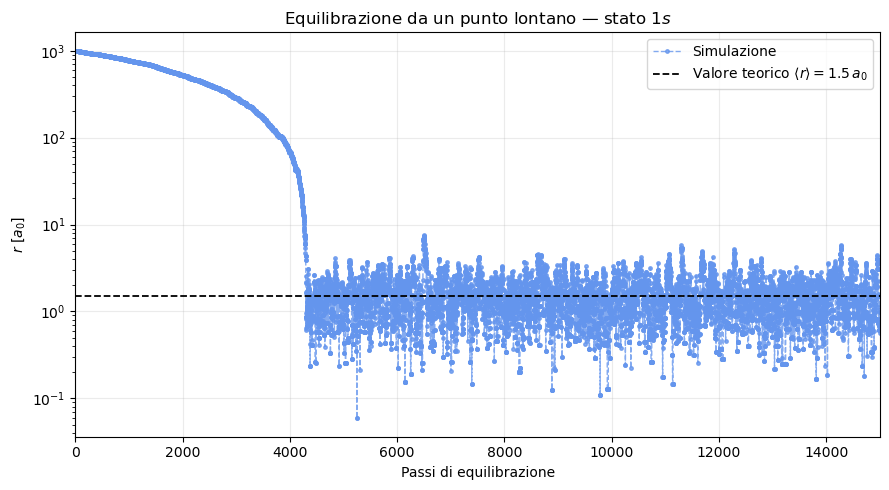

In [9]:
plt.figure(figsize=(9, 5))

plt.plot(
    steps_far_1s,
    r_far_1s,
    "o--",
    markersize=2.5,
    linewidth=1,
    color="cornflowerblue",
    alpha=0.8,
    label="Simulazione"
)

plt.axhline(
    1.5,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label=r"Valore teorico $\langle r\rangle=1.5\,a_0$"
)

plt.yscale("log")

plt.xlabel("Passi di equilibrazione")
plt.ylabel(r"$r$ [$a_0$]")
plt.title(r"Equilibrazione da un punto lontano — stato $1s$")
plt.xlim(0, 15000)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()

Partendo molto lontano dall'origine è chiaramente visibile un transiente iniziale.

La catena si trova inizialmente in una regione in cui

$$
p_{1s}(\mathbf r)\propto e^{-2r}
$$

è estremamente piccola e tende quindi a raggiungere progressivamente la regione maggiormente popolata dalla distribuzione.

Una volta raggiunto l'equilibrio, il valore istantaneo di $r$ non converge a una costante, ma continua a fluttuare.

La linea orizzontale rappresenta infatti il valor medio teorico

$$
\langle r\rangle_{1s}=1.5\,a_0,
$$

e non il valore che deve assumere ogni singola configurazione della catena.

Il transiente iniziale mostra inoltre perché le prime configurazioni generate non devono essere incluse nel calcolo delle osservabili.

### Partenza da una posizione ragionevole

La simulazione utilizzata per effettuare le misure parte invece dalla posizione

$$
\mathbf r_0=(0,0,1),
$$

che si trova già nella regione spaziale caratteristica dello stato fondamentale.

In questo caso ci si aspetta un transiente iniziale molto più breve.

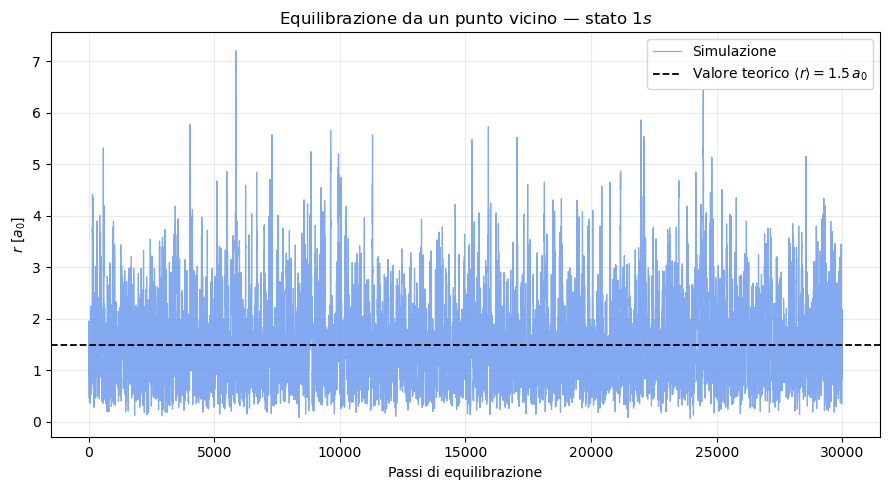

In [10]:
plt.figure(figsize=(9, 5))

plt.plot(
    steps_near_1s,
    r_near_1s,
    linewidth=0.9,
    color="cornflowerblue",
    alpha=0.8,
    label="Simulazione"
)

plt.axhline(
    1.5,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label=r"Valore teorico $\langle r\rangle=1.5\,a_0$"
)

plt.xlabel("Passi di equilibrazione")
plt.ylabel(r"$r$ [$a_0$]")
plt.title(r"Equilibrazione da un punto vicino — stato $1s$")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()

Partendo da una posizione già vicina alla regione caratteristica dello stato $1s$, la catena perde rapidamente memoria della configurazione iniziale.

Nella simulazione utilizzata per effettuare le misure sono stati comunque scartati i primi

$$
N_{\mathrm{eq}}=10^4
$$

passi Metropolis.

Questa scelta è quindi conservativa e permette di iniziare la raccolta dei dati solamente dopo che il transiente iniziale è stato eliminato.

Tutti i risultati presentati nel seguito sono ottenuti esclusivamente dalle configurazioni generate **dopo la fase di equilibrazione**.

## Stima di $\langle r\rangle$ mediante data blocking

Dopo la fase di equilibrazione vengono effettuati

$$
M=10^6
$$

passi Metropolis per ciascun orbitale.

Le misure vengono suddivise in

$$
N=100
$$

blocchi, ciascuno contenente

$$
L=\frac{M}{N}=10^4
$$

configurazioni.

Per ogni blocco viene calcolata la media

$$
\langle r\rangle_i
=
\frac{1}{L}
\sum_{j=1}^{L}r_j.
$$

Le medie dei blocchi vengono poi utilizzate per costruire la stima progressiva

$$
\langle r\rangle_{\mathrm{prog}}
$$

e la relativa incertezza statistica.

L'utilizzo del data blocking è particolarmente importante nel caso del Metropolis, poiché configurazioni successive della catena sono in generale correlate.

In [12]:
# Caricamento dei risultati della simulazione

data_1s = np.loadtxt("Esercizio_05.1/radius_1s.dat")
data_2p = np.loadtxt("Esercizio_05.1/radius_2p.dat")

# Stato 1s
blocks_1s = data_1s[:, 0]
steps_1s = data_1s[:, 1]
r_mean_1s = data_1s[:, 2]
r_err_1s = data_1s[:, 3]

# Stato 2p
blocks_2p = data_2p[:, 0]
steps_2p = data_2p[:, 1]
r_mean_2p = data_2p[:, 2]
r_err_2p = data_2p[:, 3]

# Valori teorici
r_theory_1s = 1.5
r_theory_2p = 5.0

print(
    f"Stima finale <r> 1s = "
    f"{r_mean_1s[-1]:.5f} ± {r_err_1s[-1]:.5f}"
)

print(
    f"Stima finale <r> 2p = "
    f"{r_mean_2p[-1]:.5f} ± {r_err_2p[-1]:.5f}"
)

Stima finale <r> 1s = 1.49921 ± 0.00395
Stima finale <r> 2p = 4.99538 ± 0.00962


## Stato fondamentale $1s$

Per lo stato fondamentale il valore teorico atteso è

$$
\langle r\rangle_{1s}
=
\frac{3}{2}
=
1.5.
$$

Nel grafico seguente viene mostrata la stima progressiva ottenuta mediante data blocking insieme alla relativa incertezza statistica.

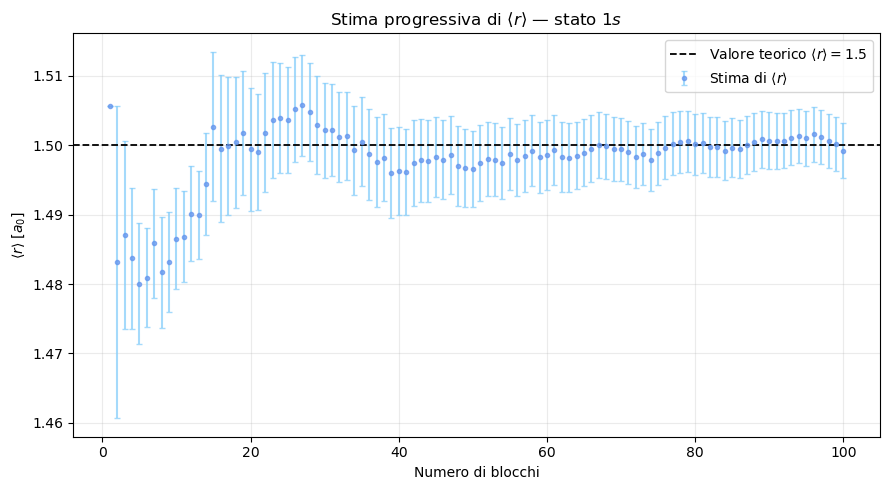

In [13]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    blocks_1s,
    r_mean_1s,
    yerr=r_err_1s,
    fmt="o",
    markersize=3,
    capsize=2,
    color="cornflowerblue",
    ecolor="lightskyblue",
    alpha=0.75,
    label=r"Stima di $\langle r\rangle$"
)

plt.axhline(
    r_theory_1s,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label=r"Valore teorico $\langle r\rangle=1.5$"
)

plt.xlabel("Numero di blocchi")
plt.ylabel(r"$\langle r\rangle$ [$a_0$]")
plt.title(r"Stima progressiva di $\langle r\rangle$ — stato $1s$")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()

La stima progressiva converge verso il valore teorico

$$
\langle r\rangle_{1s}=1.5.
$$

All'aumentare del numero di blocchi la stima diventa progressivamente più stabile e l'incertezza statistica si riduce.

Il valore teorico risulta compatibile con il risultato Monte Carlo entro le barre d'errore.

## Stato eccitato $2p$

Per lo stato eccitato considerato nell'esercizio il valore teorico è

$$
\langle r\rangle_{2p}=5.
$$

Anche in questo caso viene analizzata la convergenza della stima progressiva ottenuta mediante data blocking.

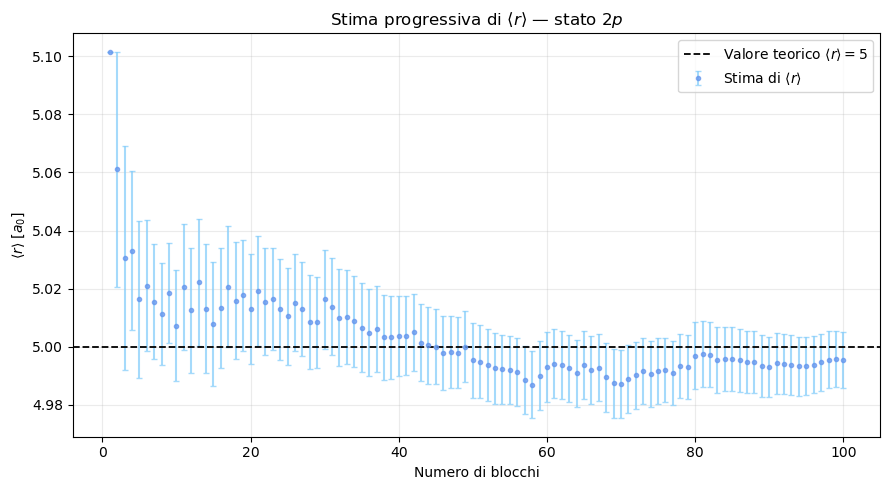

In [14]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    blocks_2p,
    r_mean_2p,
    yerr=r_err_2p,
    fmt="o",
    markersize=3,
    capsize=2,
    color="cornflowerblue",
    ecolor="lightskyblue",
    alpha=0.75,
    label=r"Stima di $\langle r\rangle$"
)

plt.axhline(
    r_theory_2p,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label=r"Valore teorico $\langle r\rangle=5$"
)

plt.xlabel("Numero di blocchi")
plt.ylabel(r"$\langle r\rangle$ [$a_0$]")
plt.title(r"Stima progressiva di $\langle r\rangle$ — stato $2p$")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()

Anche per lo stato $2p$ la stima progressiva converge verso il risultato teorico

$$
\langle r\rangle_{2p}=5.
$$

Il risultato numerico risulta compatibile con il valore atteso entro l'incertezza statistica.

La diversa estensione spaziale dei due orbitali si riflette anche nei differenti valori del passo ottimale di Metropolis: lo stato $2p$, più esteso, richiede un valore di $\Delta$ maggiore rispetto allo stato $1s$.

## Distribuzione spaziale dei punti campionati

L'algoritmo di Metropolis permette di generare configurazioni

$$
\mathbf r=(x,y,z)
$$

distribuite secondo la densità di probabilità

$$
p(\mathbf r)=|\Psi(\mathbf r)|^2.
$$

Durante la simulazione è stata salvata una configurazione ogni 100 passi Metropolis, dopo la fase di equilibrazione.

La concentrazione dei punti nello spazio fornisce quindi una rappresentazione visiva della densità di probabilità associata ai due orbitali.

È importante osservare che i punti mostrati non rappresentano una traiettoria fisica dell'elettrone, ma un insieme di campioni estratti dalla distribuzione di probabilità $|\Psi|^2$.

In [15]:
# Caricamento delle posizioni campionate dopo l'equilibrazione

positions_1s = np.loadtxt("Esercizio_05.1/positions_1s.dat")
positions_2p = np.loadtxt("Esercizio_05.1/positions_2p.dat")

# Coordinate dello stato 1s
x_1s = positions_1s[:, 0]
y_1s = positions_1s[:, 1]
z_1s = positions_1s[:, 2]

# Coordinate dello stato 2p
x_2p = positions_2p[:, 0]
y_2p = positions_2p[:, 1]
z_2p = positions_2p[:, 2]

print(f"Numero di punti salvati per 1s: {len(x_1s)}")
print(f"Numero di punti salvati per 2p: {len(x_2p)}")

Numero di punti salvati per 1s: 10000
Numero di punti salvati per 2p: 10000


### Distribuzione spaziale dello stato $1s$

Per lo stato fondamentale,

$$
|\Psi_{1,0,0}|^2
\propto
e^{-2r},
$$

la densità di probabilità dipende solamente dalla distanza dall'origine

$$
r=\sqrt{x^2+y^2+z^2}.
$$

Non esiste quindi una direzione privilegiata e ci si aspetta una distribuzione **sfericamente simmetrica**, maggiormente concentrata vicino all'origine.

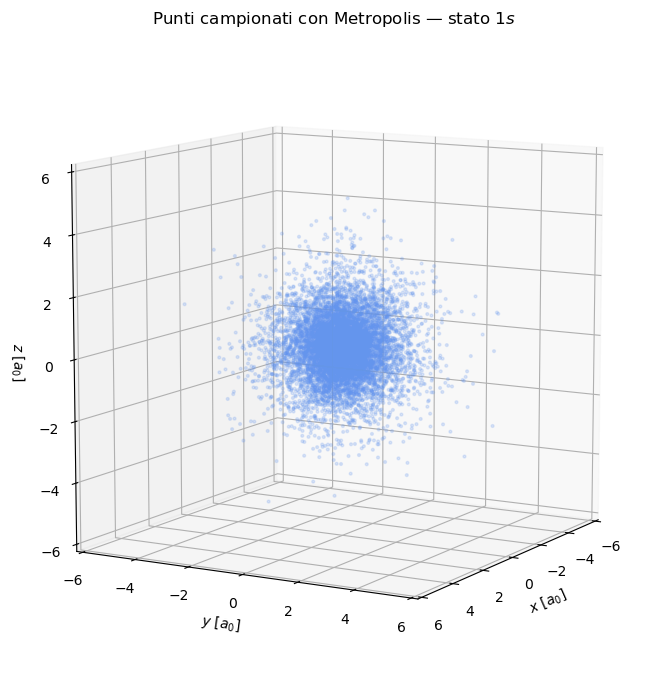

In [19]:
fig = plt.figure(figsize=(8, 7))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    x_1s,
    y_1s,
    z_1s,
    s=4,
    alpha=0.20,
    color="cornflowerblue"
)

# Utilizziamo gli stessi limiti sui tre assi
# per non deformare visivamente la distribuzione
lim_1s = np.max(
    np.abs(
        np.concatenate([x_1s, y_1s, z_1s])
    )
)

ax.set_xlim(-lim_1s, lim_1s)
ax.set_ylim(-lim_1s, lim_1s)
ax.set_zlim(-lim_1s, lim_1s)

ax.set_box_aspect((1, 1, 1))
ax.view_init(10, 30)
ax.set_xlabel(r"$x$ [$a_0$]")
ax.set_ylabel(r"$y$ [$a_0$]")
ax.set_zlabel(r"$z$ [$a_0$]")

ax.set_title(r"Punti campionati con Metropolis — stato $1s$")

plt.tight_layout()
plt.show()

La nube di punti risulta approssimativamente sferica e presenta la massima concentrazione vicino all'origine.

Questo comportamento è coerente con la forma della densità

$$
|\Psi_{1,0,0}|^2\propto e^{-2r},
$$

che dipende esclusivamente dalla distanza $r$ e diminuisce esponenzialmente all'aumentare della distanza dal nucleo.

La simulazione riproduce quindi correttamente la simmetria sferica dello stato fondamentale.

### Distribuzione spaziale dello stato $2p$

Per lo stato eccitato considerato,

$$
|\Psi_{2,1,0}|^2
\propto
z^2e^{-r}.
$$

In questo caso la densità non è più sfericamente simmetrica.

Il fattore

$$
z^2
$$

favorisce le regioni poste lungo l'asse $z$, mentre sul piano

$$
z=0
$$

la probabilità si annulla.

Ci si aspetta quindi una distribuzione costituita da due regioni principali, poste rispettivamente a $z>0$ e $z<0$, separate da un piano nodale.

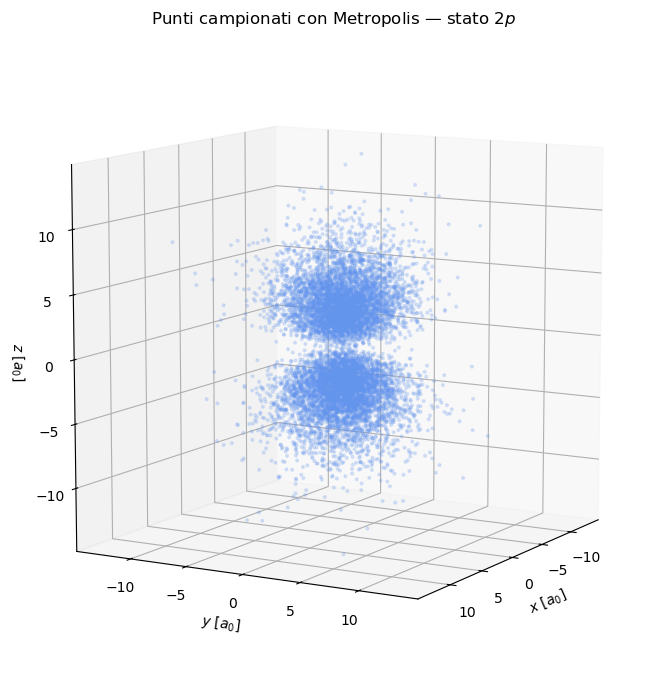

In [18]:
fig = plt.figure(figsize=(8, 7))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    x_2p,
    y_2p,
    z_2p,
    s=4,
    alpha=0.20,
    color="cornflowerblue"
)

# Utilizziamo gli stessi limiti sui tre assi
# per mantenere correttamente le proporzioni spaziali
lim_2p = np.max(
    np.abs(
        np.concatenate([x_2p, y_2p, z_2p])
    )
)

ax.set_xlim(-lim_2p, lim_2p)
ax.set_ylim(-lim_2p, lim_2p)
ax.set_zlim(-lim_2p, lim_2p)
ax.view_init(10, 30)
ax.set_box_aspect((1, 1, 1))

ax.set_xlabel(r"$x$ [$a_0$]")
ax.set_ylabel(r"$y$ [$a_0$]")
ax.set_zlabel(r"$z$ [$a_0$]")

ax.set_title(r"Punti campionati con Metropolis — stato $2p$")

plt.tight_layout()
plt.show()

La distribuzione campionata mostra una struttura nettamente diversa rispetto allo stato fondamentale.

I punti sono prevalentemente distribuiti lungo l'asse $z$ e si distinguono due regioni simmetriche rispetto all'origine.

In prossimità del piano

$$
z=0
$$

la densità dei punti diminuisce fortemente, in accordo con

$$
|\Psi_{2,1,0}|^2
\propto
z^2e^{-r},
$$

che si annulla esattamente sul piano nodale.

La maggiore estensione spaziale dello stato $2p$ rispetto allo stato $1s$ è inoltre coerente con i rispettivi valori medi del raggio,

$$
\langle r\rangle_{1s}=1.5\,a_0,
\qquad
\langle r\rangle_{2p}=5\,a_0.
$$

## Autocorrelazione e dimensione dei blocchi

Una caratteristica importante delle simulazioni Metropolis è che configurazioni successive della catena di Markov non sono statisticamente indipendenti.

Poiché ogni nuova configurazione viene proposta a partire da quella precedente, due misure effettuate a pochi passi Monte Carlo di distanza possono risultare fortemente correlate.

L'autocorrelazione normalizzata della variabile $r$ può essere definita come

$$
C(t)
=
\frac{
\langle r_i r_{i+t}\rangle
-
\langle r_i\rangle\langle r_{i+t}\rangle
}{
\sigma_r^2
}.
$$

Per $t=0$ si ha

$$
C(0)=1,
$$

mentre per tempi sufficientemente grandi ci si aspetta

$$
C(t)\rightarrow0.
$$

Il tempo di correlazione $\tau_c$ fornisce una misura della scala temporale sulla quale la catena perde memoria delle configurazioni precedenti.

La dimensione $L$ dei blocchi deve quindi essere scelta sufficientemente maggiore del tempo di correlazione, in modo che le medie di blocchi diversi possano essere considerate approssimativamente indipendenti.

In [22]:
# Caricamento delle serie temporali di r dopo l'equilibrazione

series_1s = np.loadtxt("Esercizio_05.1/series_1s.dat")
series_2p = np.loadtxt("Esercizio_05.1/series_2p.dat")

steps_series_1s = series_1s[:, 0]
r_series_1s = series_1s[:, 1]

steps_series_2p = series_2p[:, 0]
r_series_2p = series_2p[:, 1]

print(f"Numero di misure 1s: {len(r_series_1s)}")
print(f"Numero di misure 2p: {len(r_series_2p)}")

Numero di misure 1s: 1000000
Numero di misure 2p: 1000000


In [23]:
def autocorrelation_fft(data):
    """
    Calcola l'autocorrelazione normalizzata utilizzando la FFT.
    """

    data = np.asarray(data)

    # Sottrazione della media
    fluctuations = data - np.mean(data)

    n = len(fluctuations)

    # Zero-padding per evitare correlazioni circolari
    n_fft = 2 ** int(np.ceil(np.log2(2 * n)))

    fft = np.fft.rfft(fluctuations, n=n_fft)

    autocorr = np.fft.irfft(
        fft * np.conjugate(fft),
        n=n_fft
    )[:n]

    # Correzione per il numero differente di coppie
    # disponibili ai diversi lag
    autocorr /= np.arange(n, 0, -1)

    # Normalizzazione: C(0) = 1
    autocorr /= autocorr[0]

    return autocorr

### Autocorrelazione dello stato $1s$

Calcoliamo ora la funzione di autocorrelazione della distanza $r$ per le configurazioni generate dopo l'equilibrazione.

Una stima semplice del tempo di correlazione $\tau_c$ può essere ottenuta individuando il primo lag per il quale

$$
C(t)\leq e^{-1}.
$$

Questa definizione è motivata dal comportamento approssimativamente esponenziale

$$
C(t)\sim e^{-t/\tau_c}.
$$

In [24]:
# Calcolo dell'autocorrelazione per lo stato 1s

acf_1s = autocorrelation_fft(r_series_1s)

# Primo lag per il quale C(t) <= 1/e
tau_1s = np.argmax(acf_1s <= np.exp(-1))

print(f"Tempo di correlazione stimato 1s: tau_c ≈ {tau_1s} passi")

Tempo di correlazione stimato 1s: tau_c ≈ 11 passi


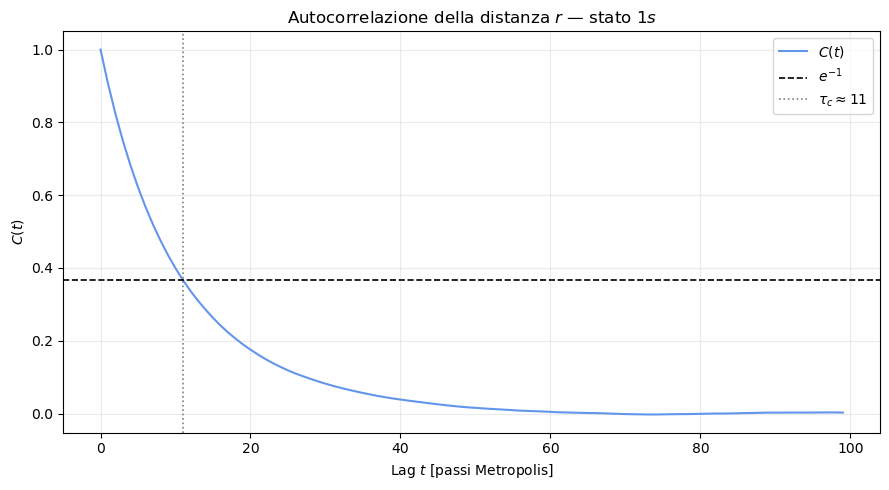

In [25]:
max_lag = 100

plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(max_lag),
    acf_1s[:max_lag],
    color="cornflowerblue",
    linewidth=1.5,
    label=r"$C(t)$"
)

plt.axhline(
    np.exp(-1),
    color="black",
    linestyle="--",
    linewidth=1.2,
    label=r"$e^{-1}$"
)

plt.axvline(
    tau_1s,
    color="gray",
    linestyle=":",
    linewidth=1.2,
    label=rf"$\tau_c \approx {tau_1s}$"
)

plt.xlabel("Lag $t$ [passi Metropolis]")
plt.ylabel(r"$C(t)$")
plt.title(r"Autocorrelazione della distanza $r$ — stato $1s$")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()

### Autocorrelazione dello stato $2p$

Ripetiamo la stessa analisi per lo stato eccitato $2p$.

Anche in questo caso il tempo di correlazione indica il numero caratteristico di passi Metropolis necessario affinché la catena perda memoria della configurazione precedente.

In [26]:
# Calcolo dell'autocorrelazione per lo stato 2p

acf_2p = autocorrelation_fft(r_series_2p)

# Primo lag per il quale C(t) <= 1/e
tau_2p = np.argmax(acf_2p <= np.exp(-1))

print(f"Tempo di correlazione stimato 2p: tau_c ≈ {tau_2p} passi")

Tempo di correlazione stimato 2p: tau_c ≈ 10 passi


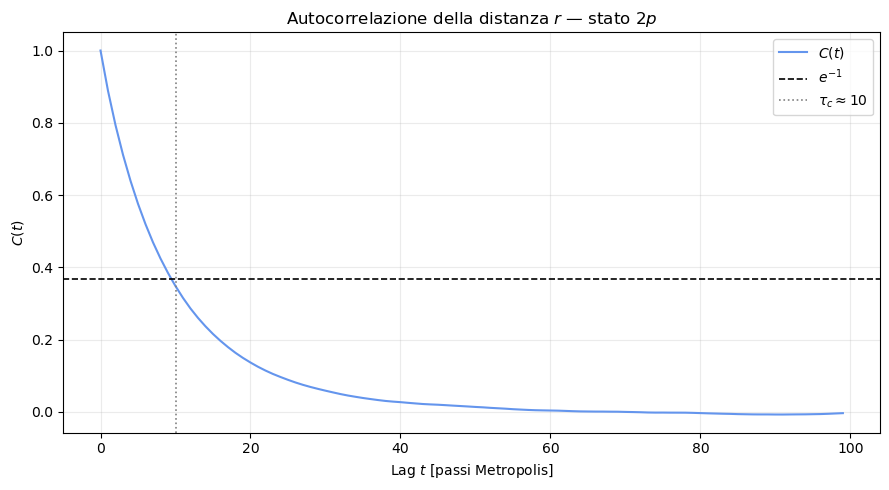

In [27]:
max_lag = 100

plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(max_lag),
    acf_2p[:max_lag],
    color="cornflowerblue",
    linewidth=1.5,
    label=r"$C(t)$"
)

plt.axhline(
    np.exp(-1),
    color="black",
    linestyle="--",
    linewidth=1.2,
    label=r"$e^{-1}$"
)

plt.axvline(
    tau_2p,
    color="gray",
    linestyle=":",
    linewidth=1.2,
    label=rf"$\tau_c \approx {tau_2p}$"
)

plt.xlabel("Lag $t$ [passi Metropolis]")
plt.ylabel(r"$C(t)$")
plt.title(r"Autocorrelazione della distanza $r$ — stato $2p$")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()

## Dipendenza dell'errore dalla dimensione dei blocchi

Un secondo metodo per verificare la scelta della dimensione dei blocchi consiste nel ricalcolare l'incertezza statistica utilizzando valori differenti di

$$
L.
$$

Per blocchi troppo piccoli, le correlazioni presenti tra configurazioni successive fanno sì che le medie dei blocchi non siano indipendenti e l'errore statistico venga sottostimato.

Aumentando $L$, ogni blocco contiene un numero sempre maggiore di tempi di correlazione e le medie dei blocchi diventano progressivamente meno correlate.

Ci si aspetta quindi che l'errore stimato aumenti inizialmente e raggiunga successivamente un plateau.

La comparsa di questo plateau permette di individuare una dimensione dei blocchi sufficientemente grande.

In [28]:
def blocking_error(data, block_size):
    """
    Calcola l'errore sulla media utilizzando blocchi
    di dimensione block_size.
    """

    n_blocks = len(data) // block_size

    # Utilizziamo solamente un numero intero di blocchi
    trimmed_data = data[:n_blocks * block_size]

    blocks = trimmed_data.reshape(
        n_blocks,
        block_size
    )

    # Media di ciascun blocco
    block_means = np.mean(blocks, axis=1)

    # Errore sulla media delle medie dei blocchi
    error = np.std(
        block_means,
        ddof=1
    ) / np.sqrt(n_blocks)

    return error

In [29]:
block_sizes = np.array([
    1,
    2,
    5,
    10,
    20,
    50,
    100,
    200,
    500,
    1000,
    2000,
    5000,
    10000
])

errors_1s = np.array([
    blocking_error(r_series_1s, L)
    for L in block_sizes
])

errors_2p = np.array([
    blocking_error(r_series_2p, L)
    for L in block_sizes
])

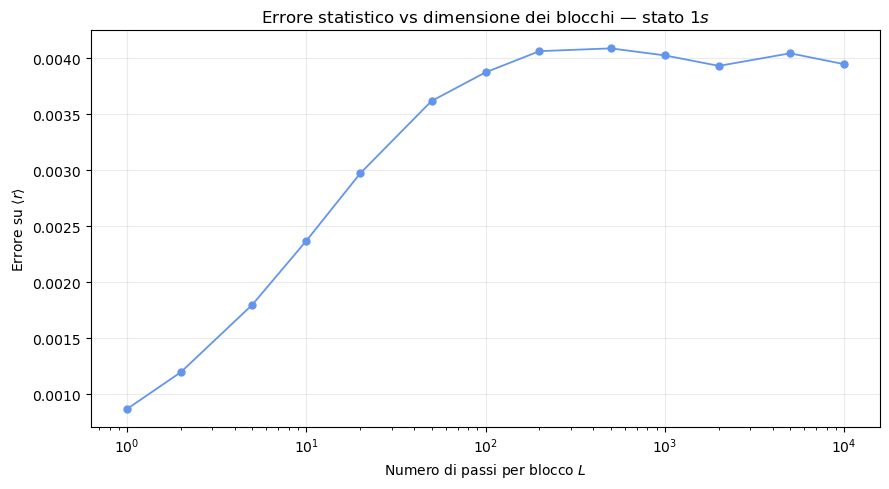

In [30]:
plt.figure(figsize=(9, 5))

plt.plot(
    block_sizes,
    errors_1s,
    "o-",
    markersize=5,
    linewidth=1.3,
    color="cornflowerblue"
)

plt.xscale("log")

plt.xlabel("Numero di passi per blocco $L$")
plt.ylabel(r"Errore su $\langle r\rangle$")
plt.title(r"Errore statistico vs dimensione dei blocchi — stato $1s$")

plt.grid(alpha=0.25)
plt.tight_layout()

plt.show()

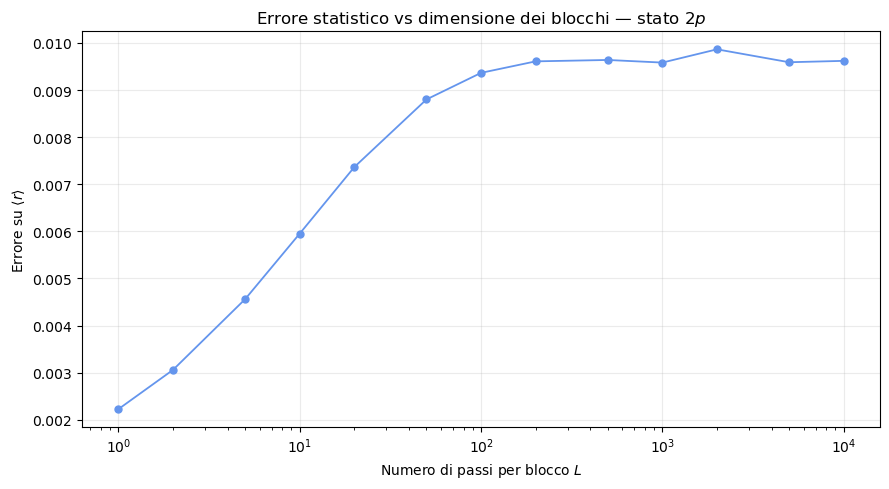

In [31]:
plt.figure(figsize=(9, 5))

plt.plot(
    block_sizes,
    errors_2p,
    "o-",
    markersize=5,
    linewidth=1.3,
    color="cornflowerblue"
)

plt.xscale("log")

plt.xlabel("Numero di passi per blocco $L$")
plt.ylabel(r"Errore su $\langle r\rangle$")
plt.title(r"Errore statistico vs dimensione dei blocchi — stato $2p$")

plt.grid(alpha=0.25)
plt.tight_layout()

plt.show()

Dai grafici si osserva che, per blocchi molto piccoli, l'errore statistico viene significativamente sottostimato.

Questo comportamento è dovuto alle correlazioni tra configurazioni Metropolis successive: utilizzando blocchi troppo corti, le medie dei diversi blocchi non possono ancora essere considerate statisticamente indipendenti.

Aumentando il numero di passi per blocco $L$, l'errore cresce fino a raggiungere un plateau.

Per entrambi gli stati il plateau viene raggiunto approssimativamente per

$$
L \gtrsim 10^2.
$$

Per lo stato $1s$ l'errore si stabilizza intorno a

$$
\sigma_{\langle r\rangle}\simeq 4\times10^{-3},
$$

mentre per lo stato $2p$ si stabilizza intorno a

$$
\sigma_{\langle r\rangle}\simeq 10^{-2}.
$$

La scelta utilizzata nella simulazione,

$$
L=10^4,
$$

è quindi ampiamente maggiore della scala necessaria per rendere trascurabili le correlazioni tra le medie dei blocchi.

Con un totale di

$$
M=10^6
$$

passi Metropolis, questa scelta corrisponde inoltre a

$$
N=\frac{M}{L}=100
$$

blocchi, un numero ancora sufficientemente grande per ottenere una stima affidabile dell'incertezza statistica.

La scelta di $L$ rappresenta quindi un compromesso: deve essere abbastanza grande rispetto al tempo di correlazione, ma non così grande da lasciare un numero troppo piccolo di blocchi.

## Transition probability gaussiana

Finora le nuove configurazioni sono state proposte utilizzando una distribuzione uniforme:

$$
x'=x+\delta_x,
\qquad
y'=y+\delta_y,
\qquad
z'=z+\delta_z,
$$

con

$$
\delta_i\sim U(-\Delta,\Delta).
$$

L'esercizio richiede di verificare se i risultati rimangono equivalenti utilizzando invece una transition probability gaussiana.

In questo caso ciascuna coordinata viene proposta secondo

$$
x'=x+\eta_x,
\qquad
y'=y+\eta_y,
\qquad
z'=z+\eta_z,
$$

dove

$$
\eta_i\sim\mathcal N(0,\sigma^2).
$$

Le tre variabili gaussiane sono generate indipendentemente.

Poiché anche la distribuzione normale centrata in zero è simmetrica,

$$
T(\mathbf r'|\mathbf r)
=
T(\mathbf r|\mathbf r'),
$$

la probabilità di accettazione di Metropolis rimane

$$
A(\mathbf r'|\mathbf r)
=
\min\left[
1,
\frac{p(\mathbf r')}{p(\mathbf r)}
\right].
$$

Il parametro $\sigma$ è stato tarato separatamente per ciascun orbitale in modo da ottenere, anche in questo caso, un'accettanza prossima al $50\%$.

In [32]:
# Caricamento dei risultati ottenuti con proposal gaussiana

data_1s_gauss = np.loadtxt("Esercizio_05.1/radius_1s_gauss.dat")
data_2p_gauss = np.loadtxt("Esercizio_05.1/radius_2p_gauss.dat")

# Stato 1s
blocks_1s_gauss = data_1s_gauss[:, 0]
r_mean_1s_gauss = data_1s_gauss[:, 2]
r_err_1s_gauss = data_1s_gauss[:, 3]

# Stato 2p
blocks_2p_gauss = data_2p_gauss[:, 0]
r_mean_2p_gauss = data_2p_gauss[:, 2]
r_err_2p_gauss = data_2p_gauss[:, 3]

print("RISULTATI FINALI")
print()

print(
    f"1s uniforme : "
    f"{r_mean_1s[-1]:.5f} ± {r_err_1s[-1]:.5f}"
)

print(
    f"1s gaussiana: "
    f"{r_mean_1s_gauss[-1]:.5f} ± {r_err_1s_gauss[-1]:.5f}"
)

print()

print(
    f"2p uniforme : "
    f"{r_mean_2p[-1]:.5f} ± {r_err_2p[-1]:.5f}"
)

print(
    f"2p gaussiana: "
    f"{r_mean_2p_gauss[-1]:.5f} ± {r_err_2p_gauss[-1]:.5f}"
)

RISULTATI FINALI

1s uniforme : 1.49921 ± 0.00395
1s gaussiana: 1.50198 ± 0.00436

2p uniforme : 4.99538 ± 0.00962
2p gaussiana: 4.98543 ± 0.01035


### Confronto tra proposal uniforme e gaussiana — stato $1s$

Confrontiamo le stime progressive di

$$
\langle r\rangle_{1s}
$$

ottenute utilizzando le due differenti transition probabilities.

Entrambe le simulazioni utilizzano lo stesso numero totale di passi, lo stesso data blocking e una probabilità di accettazione prossima al $50\%$.

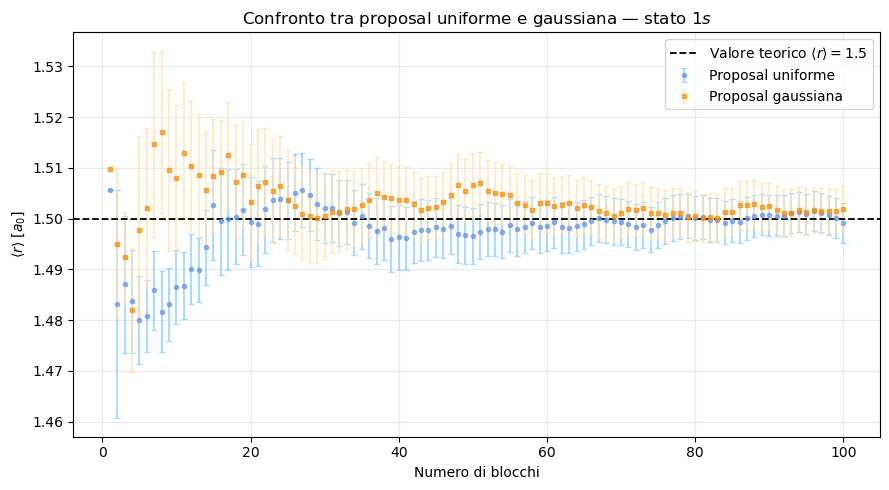

In [33]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    blocks_1s,
    r_mean_1s,
    yerr=r_err_1s,
    fmt="o",
    markersize=3,
    capsize=2,
    color="cornflowerblue",
    ecolor="lightskyblue",
    alpha=0.70,
    label="Proposal uniforme"
)

plt.errorbar(
    blocks_1s_gauss,
    r_mean_1s_gauss,
    yerr=r_err_1s_gauss,
    fmt="s",
    markersize=3,
    capsize=2,
    color="darkorange",
    ecolor="moccasin",
    alpha=0.70,
    label="Proposal gaussiana"
)

plt.axhline(
    r_theory_1s,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label=r"Valore teorico $\langle r\rangle=1.5$"
)

plt.xlabel("Numero di blocchi")
plt.ylabel(r"$\langle r\rangle$ [$a_0$]")
plt.title(
    r"Confronto tra proposal uniforme e gaussiana — stato $1s$"
)

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()

### Confronto tra proposal uniforme e gaussiana — stato $2p$

Ripetiamo lo stesso confronto per lo stato eccitato $2p$, per il quale il valore teorico è

$$
\langle r\rangle_{2p}=5.
$$

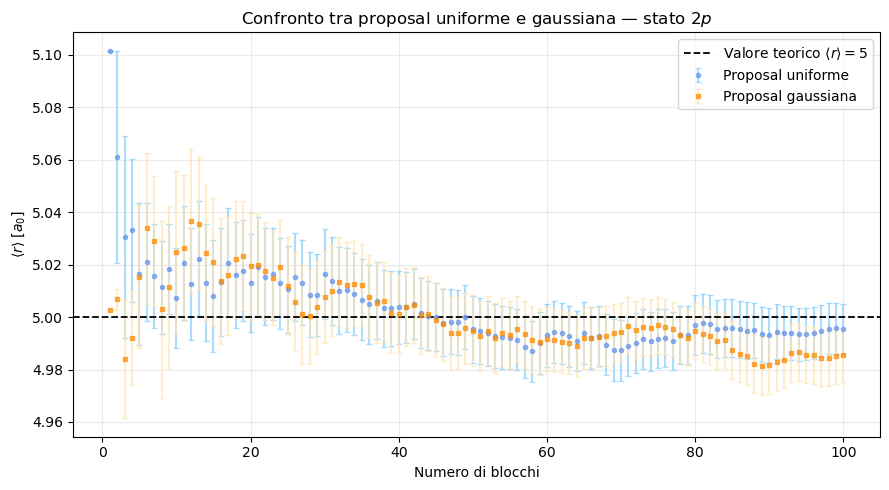

In [34]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    blocks_2p,
    r_mean_2p,
    yerr=r_err_2p,
    fmt="o",
    markersize=3,
    capsize=2,
    color="cornflowerblue",
    ecolor="lightskyblue",
    alpha=0.70,
    label="Proposal uniforme"
)

plt.errorbar(
    blocks_2p_gauss,
    r_mean_2p_gauss,
    yerr=r_err_2p_gauss,
    fmt="s",
    markersize=3,
    capsize=2,
    color="darkorange",
    ecolor="moccasin",
    alpha=0.70,
    label="Proposal gaussiana"
)

plt.axhline(
    r_theory_2p,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label=r"Valore teorico $\langle r\rangle=5$"
)

plt.xlabel("Numero di blocchi")
plt.ylabel(r"$\langle r\rangle$ [$a_0$]")
plt.title(
    r"Confronto tra proposal uniforme e gaussiana — stato $2p$"
)

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()

## Compatibilità statistica dei risultati

Per verificare quantitativamente la compatibilità tra le due simulazioni si considera la differenza

$$
\Delta =
\langle r\rangle_{\mathrm{uniforme}}
-
\langle r\rangle_{\mathrm{gaussiana}}.
$$

Assumendo indipendenti le due simulazioni, l'incertezza associata alla differenza è

$$
\sigma_{\Delta}
=
\sqrt{
\sigma_{\mathrm{uniforme}}^2
+
\sigma_{\mathrm{gaussiana}}^2
}.
$$

Si può quindi definire

$$
z=
\frac{|\Delta|}{\sigma_{\Delta}}.
$$

Un valore di $z$ dell'ordine dell'unità indica che la differenza tra i risultati è compatibile con le normali fluttuazioni statistiche.

In [35]:
def compatibility(mean_1, err_1, mean_2, err_2):

    difference = mean_1 - mean_2

    error_difference = np.sqrt(
        err_1**2 + err_2**2
    )

    z = np.abs(difference) / error_difference

    return difference, error_difference, z


# Stato 1s
delta_1s_comp, sigma_1s_comp, z_1s = compatibility(
    r_mean_1s[-1],
    r_err_1s[-1],
    r_mean_1s_gauss[-1],
    r_err_1s_gauss[-1]
)

# Stato 2p
delta_2p_comp, sigma_2p_comp, z_2p = compatibility(
    r_mean_2p[-1],
    r_err_2p[-1],
    r_mean_2p_gauss[-1],
    r_err_2p_gauss[-1]
)


print("Compatibilità uniforme - gaussiana")
print()

print(
    f"1s: Δ = {delta_1s_comp:.5f} ± "
    f"{sigma_1s_comp:.5f}"
)

print(
    f"    |Δ| / σΔ = {z_1s:.2f}"
)

print()

print(
    f"2p: Δ = {delta_2p_comp:.5f} ± "
    f"{sigma_2p_comp:.5f}"
)

print(
    f"    |Δ| / σΔ = {z_2p:.2f}"
)

Compatibilità uniforme - gaussiana

1s: Δ = -0.00277 ± 0.00588
    |Δ| / σΔ = 0.47

2p: Δ = 0.00995 ± 0.01413
    |Δ| / σΔ = 0.70


Le simulazioni effettuate con transition probability uniforme e gaussiana forniscono risultati statisticamente compatibili.

Per lo stato $1s$ si ottiene

$$
\Delta
=
\langle r\rangle_{\mathrm{uniforme}}
-
\langle r\rangle_{\mathrm{gaussiana}}
=
-0.00277 \pm 0.00588,
$$

corrispondente a

$$
\frac{|\Delta|}{\sigma_\Delta}=0.47.
$$

Per lo stato $2p$ si ottiene invece

$$
\Delta
=
0.00995 \pm 0.01413,
$$

con

$$
\frac{|\Delta|}{\sigma_\Delta}=0.70.
$$

In entrambi i casi la differenza tra i risultati è inferiore a una deviazione standard combinata.

Non emerge quindi alcuna differenza statisticamente significativa tra le stime ottenute con proposal uniforme e gaussiana.

Questo conferma che entrambe le transition probabilities permettono di campionare correttamente la stessa distribuzione target. La scelta della proposal non modifica il valore di equilibrio dell'osservabile, ma può influenzare l'efficienza della random walk, il tasso di accettazione e le correlazioni tra configurazioni successive.

## Conclusioni

L'algoritmo di Metropolis è stato utilizzato per campionare le densità di probabilità degli stati $1s$ e $2p$ dell'atomo di idrogeno.

Dopo una fase iniziale di tuning della transition probability e di equilibrazione della catena, sono stati utilizzati $10^6$ passi Metropolis per stimare il valor medio del raggio.

Mediante data blocking sono stati ottenuti risultati compatibili con i valori teorici

$$
\langle r\rangle_{1s}=1.5\,a_0,
\qquad
\langle r\rangle_{2p}=5\,a_0.
$$

Lo studio dell'autocorrelazione e della dipendenza dell'errore dalla dimensione dei blocchi ha mostrato la presenza di correlazioni tra configurazioni Metropolis successive e ha permesso di verificare che la scelta

$$
L=10^4
$$

passi per blocco è ampiamente sufficiente.

La distribuzione spaziale dei punti campionati riproduce inoltre le caratteristiche attese dei due orbitali: simmetria sferica per lo stato $1s$ e struttura a due lobi, separati dal piano nodale $z=0$, per lo stato $2p$.

Infine, il confronto tra transition probability uniforme e gaussiana fornisce risultati statisticamente compatibili, mostrando che entrambe permettono di campionare correttamente la stessa distribuzione target.